# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Muhammad Fajriansyah Al Amin
- **Email:** muhammadfajriansyah0206@gmail.com
- **ID Dicoding:** DS269B6Y1138

## Menentukan Pertanyaan Bisnis

## Deskripsi Proyek

Proyek ini bertujuan untuk menganalisis pola konsentrasi
partikulat PM2.5 pada 12 stasiun pemantauan kualitas udara
di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017.

Analisis dilakukan untuk mengidentifikasi perubahan konsentrasi
PM2.5 dari waktu ke waktu serta perbedaan tingkat polusi
antarstasiun pemantauan.

Proyek mencakup proses data wrangling, exploratory data
analysis (EDA), data visualization, advanced analysis,
serta penyusunan kesimpulan dan rekomendasi.

Hasil analisis akan disajikan melalui dashboard interaktif
menggunakan Streamlit.




**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

## Menentukan Pertanyaan Bisnis

1. Bagaimana perubahan rata-rata konsentrasi PM2.5 tahunan
   di 12 stasiun pemantauan Beijing selama periode
   Maret 2013 hingga Februari 2017, dan pada tahun kalender
   lengkap 2014–2016 manakah konsentrasi rata-ratanya
   paling tinggi?

2. Stasiun pemantauan manakah yang memiliki rata-rata
   konsentrasi PM2.5 tertinggi dan terendah di Beijing
   selama periode 1 Maret 2013 hingga 28 Februari 2017,
   serta berapa besar selisih konsentrasi antara
   kedua stasiun tersebut?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

## Data Wrangling

#### Memuat dan Menggabungkan Dataset

Pada tahap Gathering Data, dilakukan proses pengumpulan dan pemuatan data kualitas udara dari Beijing Multi-Site Air Quality Dataset.

Dataset terdiri dari 12 file CSV yang merepresentasikan 12 stasiun pemantauan kualitas udara di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017.

Seluruh file CSV akan digabungkan menjadi satu DataFrame menggunakan library Pandas untuk mempermudah proses analisis.

Tahapan yang dilakukan meliputi:

1. Membaca file dataset dalam format ZIP.
2. Mengidentifikasi seluruh file CSV.
3. Memuat setiap file CSV menjadi DataFrame.
4. Menggabungkan seluruh DataFrame.
5. Memeriksa dimensi, struktur, dan sampel data hasil penggabungan.

### Gathering Data

#### Memuat 12 File CSV dari Arsip Dataset Kualitas Udara Beijing

Dataset dimuat langsung dari arsip ZIP, kemudian digabungkan menjadi satu DataFrame untuk dianalisis.


In [2]:
# Menentukan lokasi dari dataset
zip_path = "data/Air-quality-dataset.zip"

# Membaca dataset ZIP
with zipfile.ZipFile(zip_path, "r") as zip_ref:

    # Mengidentifikasi seluruh file CSV
    csv_files = sorted([
        file for file in zip_ref.namelist()
        if file.endswith(".csv")
    ])

    # Menyimpan DataFrame sementara
    dataframes = []

    for file in csv_files:

        with zip_ref.open(file) as csv_file:
            temp_df = pd.read_csv(csv_file)

        dataframes.append(temp_df)

        print(f"Berhasil memuat: {os.path.basename(file)}")

# Menggabungkan seluruh DataFrame
air_quality_df = pd.concat(
    dataframes,
    ignore_index=True
)

#Melihat Dataset sampel
air_quality_df.head()
air_quality_df.sample(5, random_state=42)

station_counts = (
    air_quality_df["station"]
    .value_counts()
    .sort_index()
)

station_counts

print("\nJumlah file CSV:", len(csv_files))
print("Jumlah baris:", air_quality_df.shape[0])
print("Jumlah kolom:", air_quality_df.shape[1])

# Menampilkan dimensi dataset
print("Dimensi dataset:", air_quality_df.shape)

# Menampilkan nama kolom
print("\nDaftar kolom:")
print(air_quality_df.columns.tolist())

# Menampilkan informasi dataset
print("\nInformasi dataset:")
air_quality_df.info()

Berhasil memuat: PRSA_Data_Aotizhongxin_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Changping_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Dingling_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Dongsi_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Guanyuan_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Gucheng_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Huairou_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Nongzhanguan_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Shunyi_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Tiantan_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Wanliu_20130301-20170228.csv
Berhasil memuat: PRSA_Data_Wanshouxigong_20130301-20170228.csv

Jumlah file CSV: 12
Jumlah baris: 420768
Jumlah kolom: 18
Dimensi dataset: (420768, 18)

Daftar kolom:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'

**Insight:**

- Dataset Beijing Multi-Site Air Quality terdiri dari 12 file CSV yang berhasil digabungkan menjadi satu DataFrame dengan total 420.768 baris dan 18 kolom.
- Dataset mencakup 12 stasiun pemantauan kualitas udara dengan masing-masing stasiun memiliki 35.064 observasi per jam selama periode 1 Maret 2013 hingga 28 Februari 2017.
- Variabel PM2.5 menjadi fokus utama analisis karena dapat digunakan untuk mengidentifikasi pola perubahan konsentrasi polusi berdasarkan waktu dan lokasi stasiun pemantauan.
- Informasi waktu dan stasiun memungkinkan analisis temporal dan perbandingan antarstasiun untuk menjawab dua pertanyaan bisnis yang telah ditentukan.
- Dataset masih berupa data mentah sehingga diperlukan pemeriksaan kualitas data pada tahap Assessing Data sebelum digunakan dalam analisis lebih lanjut.

### Assessing Data

#### Mengidentifikasi Missing Values, Duplikasi, dan Nilai Tidak Wajar


In [3]:
# Memeriksa struktur dan tipe data
air_quality_df.info()

# Memeriksa tipe data setiap kolom
air_quality_df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object

In [4]:
# Menghitung missing values pada setiap kolom
missing_values = air_quality_df.isnull().sum()

# Menghitung persentase missing values
missing_percentage = (
    air_quality_df.isnull().sum()
    / len(air_quality_df)
) * 100

# Membuat tabel ringkasan
missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

# Mengurutkan berdasarkan jumlah missing values
missing_df = missing_df.sort_values(
    by="Missing Values",
    ascending=False
)

missing_df

,Missing Values,Percentage (%)
CO,20701,4.919813
O3,13277,3.155421
NO2,12116,2.879497
SO2,9021,2.143937
PM2.5,8739,2.076916
PM10,6449,1.532674
wd,1822,0.433018
DEWP,403,0.095777
TEMP,398,0.094589
PRES,393,0.093401


In [5]:
# Menghitung jumlah baris duplikat
duplicate_count = air_quality_df.duplicated().sum()

print("Jumlah duplicate rows:", duplicate_count)


# Menentukan kolom identitas pengamatan
key_columns = [
    "station",
    "year",
    "month",
    "day",
    "hour"
]

# Memeriksa duplikasi berdasarkan identitas pengamatan
duplicate_key = air_quality_df.duplicated(
    subset=key_columns
).sum()

print("Jumlah duplikasi berdasarkan stasiun dan waktu:", duplicate_key)

Jumlah duplicate rows: 0
Jumlah duplikasi berdasarkan stasiun dan waktu: 0


In [6]:
# Kolom yang tidak boleh memiliki nilai negatif
non_negative_columns = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "RAIN",
    "WSPM"
]

# Menghitung nilai negatif
negative_values = (
    air_quality_df[non_negative_columns] < 0
).sum()

print("Jumlah nilai negatif pada setiap kolom:")
print(negative_values)

Jumlah nilai negatif pada setiap kolom:
PM2.5    0
PM10     0
SO2      0
NO2      0
CO       0
O3       0
RAIN     0
WSPM     0
dtype: int64


In [7]:
# Menampilkan statistik deskriptif PM2.5
air_quality_df["PM2.5"].describe()

# Menghitung kuartil
Q1 = air_quality_df["PM2.5"].quantile(0.25)
Q3 = air_quality_df["PM2.5"].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Mengidentifikasi outlier
outliers = air_quality_df[
    (air_quality_df["PM2.5"] < lower_bound) |
    (air_quality_df["PM2.5"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Jumlah Outlier:", len(outliers))

print(
    "Persentase Outlier:",
    round(
        len(outliers) / air_quality_df["PM2.5"].count() * 100,
        2
    ),
    "%"
)

Q1: 20.0
Q3: 111.0
IQR: 91.0
Lower Bound: -116.5
Upper Bound: 247.5
Jumlah Outlier: 19142
Persentase Outlier: 4.65 %


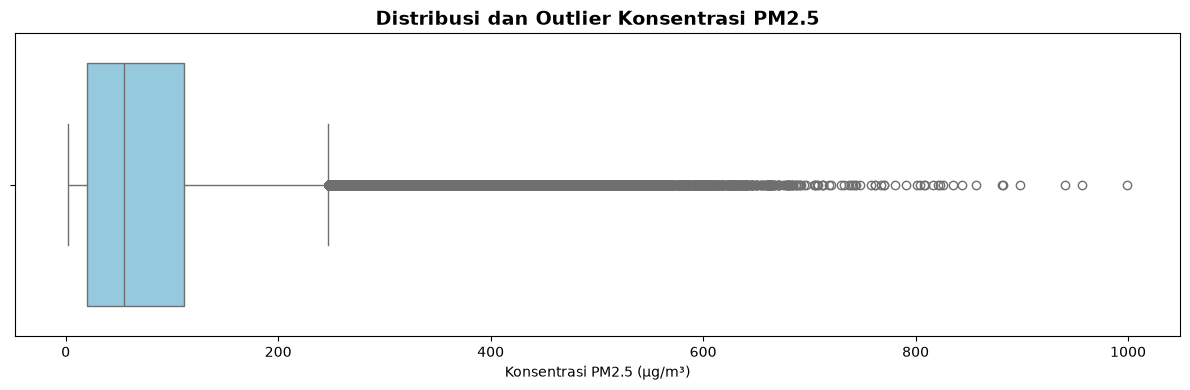

In [8]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=air_quality_df["PM2.5"],
    color="skyblue"
)

plt.title(
    "Distribusi dan Outlier Konsentrasi PM2.5",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Konsentrasi PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

In [9]:
print("Jumlah stasiun:", air_quality_df["station"].nunique())

print("\nDaftar stasiun:")
print(sorted(air_quality_df["station"].unique()))

Jumlah stasiun: 12

Daftar stasiun:
['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


In [10]:
print("Kategori arah angin:")

print(
    sorted(
        air_quality_df["wd"].dropna().unique()
    )
)

Kategori arah angin:
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


### Steps to Take

Berdasarkan hasil Assessing Data, ditentukan beberapa tindakan untuk mempersiapkan dataset sebelum digunakan dalam proses analisis.

| No. | Permasalahan | Hasil Identifikasi | Tindakan yang Akan Dilakukan |
|---|---|---|---|
| 1 | Missing Values | Ditemukan nilai kosong pada sejumlah variabel, termasuk PM2.5 sebanyak 8.739 data. | Mempertahankan nilai kosong pada dataset utama dan mengecualikannya dari perhitungan statistik PM2.5 yang memerlukan nilai valid. |
| 2 | Duplicate Data | Tidak ditemukan duplikasi berdasarkan seluruh kolom maupun kombinasi stasiun dan waktu. | Tidak diperlukan penghapusan data duplikat. |
| 3 | Invalid Values | Tidak ditemukan nilai negatif pada variabel polutan, curah hujan, dan kecepatan angin. | Tidak diperlukan koreksi nilai negatif. |
| 4 | Outliers | Pemeriksaan IQR digunakan untuk mengidentifikasi nilai ekstrem PM2.5. | Mempertahankan outlier karena berpotensi merepresentasikan kejadian polusi ekstrem. |
| 5 | Format Waktu | Informasi waktu masih dipisahkan dalam kolom year, month, day, dan hour. | Menggabungkan informasi waktu menjadi satu kolom datetime menggunakan Pandas. |
| 6 | Urutan Data | Data berasal dari penggabungan 12 file CSV. | Mengurutkan data berdasarkan stasiun dan waktu pengamatan. |

**Strategi Cleaning Data:**

Proses pembersihan akan menggunakan pendekatan yang mempertahankan informasi penting dalam dataset.

Missing values dan outlier tidak akan dihapus secara otomatis karena tindakan tersebut berpotensi memengaruhi representasi kondisi kualitas udara.

Untuk menjawab pertanyaan bisnis, perhitungan rata-rata PM2.5 hanya akan menggunakan pengamatan yang memiliki nilai PM2.5 valid.

Selain itu, jumlah pengamatan valid akan diperiksa agar perbandingan antarperiode dan antarstasiun dapat diinterpretasikan secara tepat.

#### Insight Assessing Data

Berdasarkan hasil pemeriksaan kualitas data pada Beijing Multi-Site Air Quality Dataset, diperoleh beberapa temuan berikut.

**1. Missing Values**

Ditemukan missing values pada 12 kolom dataset. Kolom CO memiliki jumlah missing values terbanyak, yaitu 20.701 data (4,92%), sedangkan variabel utama PM2.5 memiliki 8.739 missing values (2,08%).

Missing values pada PM2.5 perlu diperhatikan karena dapat memengaruhi perhitungan konsentrasi rata-rata berdasarkan waktu dan stasiun.

**2. Duplicate Data**

Tidak ditemukan duplikasi baris identik maupun duplikasi berdasarkan kombinasi stasiun, tahun, bulan, tanggal, dan jam. Dengan demikian, tidak diperlukan penghapusan data duplikat.

**3. Invalid Values**

Tidak ditemukan nilai negatif pada variabel konsentrasi polutan, curah hujan, dan kecepatan angin.

**4. Outliers**

Pemeriksaan menggunakan metode Interquartile Range (IQR) dilakukan untuk mengidentifikasi nilai PM2.5 yang berada jauh di luar distribusi utama.

Outlier statistik tidak langsung dianggap sebagai kesalahan data karena konsentrasi polutan yang sangat tinggi dapat merepresentasikan kejadian polusi ekstrem.

**5. Konsistensi Data**

Dataset memiliki 12 stasiun pemantauan dan 16 kategori arah angin yang sesuai dengan sistem arah kompas.

Informasi waktu masih tersimpan dalam kolom terpisah sehingga perlu dilakukan pembentukan kolom datetime pada tahap Cleaning Data.

#### Rencana Penanganan Data

Berdasarkan hasil pemeriksaan, tindakan yang akan dilakukan pada tahap Cleaning Data adalah:

1. Membentuk kolom datetime dari informasi tahun, bulan, tanggal, dan jam.
2. Mempertahankan missing values pada PM2.5 dan mengecualikannya dari perhitungan statistik yang membutuhkan nilai valid.
3. Mempertahankan outlier PM2.5 karena berpotensi merepresentasikan kondisi polusi ekstrem.
4. Memastikan data tersusun berdasarkan stasiun dan waktu pengamatan.
5. Melakukan validasi ulang setelah proses pembersihan untuk memastikan dataset siap digunakan dalam analisis.

### Cleaning Data

#### Membersihkan dan Menyiapkan Data PM2.5 untuk Analisis


In [11]:
# Membuat salinan dataset mentah
clean_df = air_quality_df.copy()

print("Dimensi dataset sebelum cleaning:", air_quality_df.shape)
print("Dimensi salinan dataset:", clean_df.shape)

Dimensi dataset sebelum cleaning: (420768, 18)
Dimensi salinan dataset: (420768, 18)


In [12]:
# Menggabungkan kolom waktu menjadi datetime
clean_df["datetime"] = pd.to_datetime(
    clean_df[["year", "month", "day", "hour"]],
    errors="coerce"
)

# Menampilkan hasil transformasi
clean_df[
    ["year", "month", "day", "hour", "datetime"]
].head()

,year,month,day,hour,datetime
0,2013,3,1,0,2013-03-01 00:00:00
1,2013,3,1,1,2013-03-01 01:00:00
2,2013,3,1,2,2013-03-01 02:00:00
3,2013,3,1,3,2013-03-01 03:00:00
4,2013,3,1,4,2013-03-01 04:00:00


In [13]:
# Memeriksa tipe data datetime
print("Tipe data datetime:")
print(clean_df["datetime"].dtype)

# Memeriksa datetime yang gagal dikonversi
invalid_datetime = clean_df["datetime"].isna().sum()

print("\nJumlah datetime tidak valid:", invalid_datetime)

# Memeriksa rentang waktu
print("\nTanggal awal:", clean_df["datetime"].min())
print("Tanggal akhir:", clean_df["datetime"].max())

Tipe data datetime:
datetime64[ns]

Jumlah datetime tidak valid: 0

Tanggal awal: 2013-03-01 00:00:00
Tanggal akhir: 2017-02-28 23:00:00


In [14]:
# Mengurutkan dataset berdasarkan stasiun dan waktu
clean_df = clean_df.sort_values(
    by=["station", "datetime"],
    ascending=[True, True]
).reset_index(drop=True)

# Menampilkan hasil
clean_df[
    ["station", "datetime", "PM2.5"]
].head(10)

,station,datetime,PM2.5
0,Aotizhongxin,2013-03-01 00:00:00,4.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0
5,Aotizhongxin,2013-03-01 05:00:00,5.0
6,Aotizhongxin,2013-03-01 06:00:00,3.0
7,Aotizhongxin,2013-03-01 07:00:00,3.0
8,Aotizhongxin,2013-03-01 08:00:00,3.0
9,Aotizhongxin,2013-03-01 09:00:00,3.0


In [15]:
# Menghitung missing values sebelum penanganan
missing_before = clean_df["PM2.5"].isna().sum()

valid_before = clean_df["PM2.5"].notna().sum()

print("Jumlah total pengamatan:", len(clean_df))
print("Jumlah PM2.5 valid:", valid_before)
print("Jumlah PM2.5 missing:", missing_before)

Jumlah total pengamatan: 420768
Jumlah PM2.5 valid: 412029
Jumlah PM2.5 missing: 8739


In [16]:
# Membuat dataset dengan PM2.5 valid
pm25_df = clean_df.dropna(
    subset=["PM2.5"]
).copy()

# Mengatur ulang indeks
pm25_df = pm25_df.reset_index(drop=True)

print("Dataset utama:", clean_df.shape)
print("Dataset PM2.5 valid:", pm25_df.shape)

print(
    "\nMissing values PM2.5 setelah seleksi:",
    pm25_df["PM2.5"].isna().sum()
)

Dataset utama: (420768, 19)
Dataset PM2.5 valid: (412029, 19)

Missing values PM2.5 setelah seleksi: 0


In [17]:
# Menghitung batas outlier pada PM2.5 valid
Q1_clean = pm25_df["PM2.5"].quantile(0.25)
Q3_clean = pm25_df["PM2.5"].quantile(0.75)

IQR_clean = Q3_clean - Q1_clean

lower_bound_clean = Q1_clean - 1.5 * IQR_clean
upper_bound_clean = Q3_clean + 1.5 * IQR_clean

# Mengidentifikasi outlier
outlier_mask = (
    (pm25_df["PM2.5"] < lower_bound_clean) |
    (pm25_df["PM2.5"] > upper_bound_clean)
)

print("Jumlah outlier yang dipertahankan:", outlier_mask.sum())

print(
    "Persentase outlier:",
    round(outlier_mask.mean() * 100, 2),
    "%"
)

print("\nJumlah data PM2.5 tetap:", len(pm25_df))

Jumlah outlier yang dipertahankan: 19142
Persentase outlier: 4.65 %

Jumlah data PM2.5 tetap: 412029


In [18]:
# Validasi dataset setelah cleaning

print("=== VALIDASI DATASET UTAMA ===")

print("Jumlah baris:", len(clean_df))
print("Jumlah kolom:", clean_df.shape[1])

print("Jumlah stasiun:", clean_df["station"].nunique())

print("Tanggal awal:", clean_df["datetime"].min())
print("Tanggal akhir:", clean_df["datetime"].max())

print(
    "Jumlah missing PM2.5:",
    clean_df["PM2.5"].isna().sum()
)

print(
    "Jumlah duplikasi stasiun-waktu:",
    clean_df.duplicated(
        subset=["station", "datetime"]
    ).sum()
)

print("\n=== VALIDASI DATASET ANALISIS PM2.5 ===")

print("Jumlah baris:", len(pm25_df))

print(
    "Jumlah missing PM2.5:",
    pm25_df["PM2.5"].isna().sum()
)

print(
    "Jumlah stasiun:",
    pm25_df["station"].nunique()
)

=== VALIDASI DATASET UTAMA ===
Jumlah baris: 420768
Jumlah kolom: 19
Jumlah stasiun: 12
Tanggal awal: 2013-03-01 00:00:00
Tanggal akhir: 2017-02-28 23:00:00
Jumlah missing PM2.5: 8739
Jumlah duplikasi stasiun-waktu: 0

=== VALIDASI DATASET ANALISIS PM2.5 ===
Jumlah baris: 412029
Jumlah missing PM2.5: 0
Jumlah stasiun: 12


In [19]:
# Menghitung kelengkapan PM2.5 per stasiun

station_completeness = (
    clean_df.groupby("station")
    .agg(
        total_observations=("PM2.5", "size"),
        valid_observations=("PM2.5", "count")
    )
    .reset_index()
)

station_completeness["missing_observations"] = (
    station_completeness["total_observations"]
    - station_completeness["valid_observations"]
)

station_completeness["completeness_percentage"] = (
    station_completeness["valid_observations"]
    / station_completeness["total_observations"]
    * 100
)

station_completeness.sort_values(
    by="completeness_percentage",
    ascending=True
)

,station,total_observations,valid_observations,missing_observations,completeness_percentage
6,Huairou,35064,34111,953,97.282113
0,Aotizhongxin,35064,34139,925,97.361967
8,Shunyi,35064,34151,913,97.396190
2,Dingling,35064,34285,779,97.778348
1,Changping,35064,34290,774,97.792608
3,Dongsi,35064,34314,750,97.861054
11,Wanshouxigong,35064,34368,696,98.015058
9,Tiantan,35064,34387,677,98.069245
5,Gucheng,35064,34418,646,98.157655
7,Nongzhanguan,35064,34436,628,98.208989


In [20]:
# Menyimpan dataset utama
clean_df.to_csv(
    "air_quality_clean.csv",
    index=False
)

# Menyimpan dataset khusus PM2.5
pm25_df.to_csv(
    "pm25_analysis.csv",
    index=False
)

print("Dataset berhasil disimpan!")
print("1. air_quality_clean.csv")
print("2. pm25_analysis.csv")

Dataset berhasil disimpan!
1. air_quality_clean.csv
2. pm25_analysis.csv


### Insight Cleaning Data

Berdasarkan proses Cleaning Data, diperoleh beberapa hasil sebagai berikut.

**1. Transformasi Format Waktu Berhasil Dilakukan**

Informasi waktu yang sebelumnya tersimpan dalam empat kolom terpisah, yaitu `year`, `month`, `day`, dan `hour`, telah digabungkan menjadi satu kolom `datetime`.

Transformasi ini memungkinkan analisis perubahan konsentrasi PM2.5 berdasarkan periode waktu tertentu.

**2. Missing Values Ditangani Sesuai Kebutuhan Analisis**

Dataset utama tetap mempertahankan seluruh 420.768 pengamatan, termasuk nilai PM2.5 yang kosong.

Untuk kebutuhan analisis, dibuat dataset khusus PM2.5 yang berisi 412.029 pengamatan valid setelah mengecualikan 8.739 pengamatan dengan nilai PM2.5 kosong.

Pendekatan ini dipilih untuk menghindari perubahan distribusi konsentrasi PM2.5 akibat imputasi.

**3. Nilai Ekstrem PM2.5 Dipertahankan**

Outlier yang teridentifikasi menggunakan metode IQR tidak dihapus karena berpotensi merepresentasikan kejadian polusi udara ekstrem.

Keputusan ini bertujuan untuk mempertahankan variasi konsentrasi PM2.5 yang tercatat dalam dataset.

**4. Dataset Diurutkan Secara Kronologis**

Dataset telah diurutkan berdasarkan stasiun dan waktu pengamatan sehingga memiliki struktur yang konsisten untuk analisis temporal dan perbandingan antarstasiun.

**5. Dataset Siap Digunakan untuk Analisis**

Dataset hasil cleaning telah dipersiapkan untuk menjawab dua pertanyaan bisnis utama:

- Analisis perubahan rata-rata konsentrasi PM2.5 berdasarkan tahun.
- Analisis perbandingan rata-rata konsentrasi PM2.5 antarstasiun pemantauan.

Dataset juga telah disimpan dalam format CSV untuk mendukung proses EDA, visualisasi, dan pengembangan dashboard Streamlit.

### Kesimpulan Cleaning Data

Proses Cleaning Data difokuskan pada transformasi struktur waktu, penanganan missing values berdasarkan kebutuhan analisis, dan pemeliharaan informasi konsentrasi polutan yang tercatat.

Dataset hasil cleaning siap digunakan untuk tahap Exploratory Data Analysis (EDA), dengan tetap mempertimbangkan potensi keterbatasan akibat pengamatan PM2.5 yang tidak lengkap.

## Exploratory Data Analysis (EDA)

### Eksplorasi Statistik, Tren Temporal, dan Perbandingan Antarstasiun


In [21]:
# Menampilkan statistik deskriptif PM2.5
pm25_df["PM2.5"].describe()

count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

In [22]:
# Menghitung statistik tambahan
pm25_statistics = pd.DataFrame({
    "Metric": [
        "Total Observasi",
        "Rata-rata PM2.5",
        "Median PM2.5",
        "Standar Deviasi",
        "Minimum PM2.5",
        "Maksimum PM2.5"
    ],
    "Value": [
        pm25_df["PM2.5"].count(),
        pm25_df["PM2.5"].mean(),
        pm25_df["PM2.5"].median(),
        pm25_df["PM2.5"].std(),
        pm25_df["PM2.5"].min(),
        pm25_df["PM2.5"].max()
    ]
})

pm25_statistics

,Metric,Value
0,Total Observasi,412029.000000
1,Rata-rata PM2.5,79.793428
2,Median PM2.5,55.000000
3,Standar Deviasi,80.822391
4,Minimum PM2.5,2.000000
5,Maksimum PM2.5,999.000000


In [23]:
# Mengelompokkan data berdasarkan tahun
annual_pm25 = (
    clean_df.groupby("year")
    .agg(
        mean_pm25=("PM2.5", "mean"),
        median_pm25=("PM2.5", "median"),
        max_pm25=("PM2.5", "max"),
        valid_observations=("PM2.5", "count"),
        total_observations=("PM2.5", "size")
    )
    .reset_index()
)

# Menghitung persentase kelengkapan data
annual_pm25["completeness_percentage"] = (
    annual_pm25["valid_observations"]
    / annual_pm25["total_observations"]
    * 100
)

# Membulatkan hasil
annual_pm25.round(2)

,year,mean_pm25,median_pm25,max_pm25,valid_observations,total_observations,completeness_percentage
0,2013,80.04,59.0,844.0,86897,88128,98.60
1,2014,85.58,63.0,809.0,102260,105120,97.28
2,2015,79.63,52.0,762.0,102993,105120,97.98
3,2016,71.93,48.0,999.0,103151,105408,97.86
4,2017,92.68,46.0,835.0,16728,16992,98.45


In [24]:
# Memilih tahun kalender lengkap
annual_complete = annual_pm25[
    annual_pm25["year"].between(2014, 2016)
].copy()

# Mengurutkan berdasarkan tahun
annual_complete = annual_complete.sort_values("year")

# Menghitung perubahan persentase tahunan
annual_complete["yoy_change_percentage"] = (
    annual_complete["mean_pm25"].pct_change() * 100
)

annual_complete.round(2)

,year,mean_pm25,median_pm25,max_pm25,valid_observations,total_observations,completeness_percentage,yoy_change_percentage
1,2014,85.58,63.0,809.0,102260,105120,97.28,NaN
2,2015,79.63,52.0,762.0,102993,105120,97.98,-6.95
3,2016,71.93,48.0,999.0,103151,105408,97.86,-9.67


In [25]:
# Mengidentifikasi tahun dengan rata-rata PM2.5 tertinggi
highest_year = annual_complete.loc[
    annual_complete["mean_pm25"].idxmax()
]

# Mengidentifikasi tahun dengan rata-rata PM2.5 terendah
lowest_year = annual_complete.loc[
    annual_complete["mean_pm25"].idxmin()
]

print("=== HASIL ANALISIS TEMPORAL ===")

print(
    f"Tahun dengan rata-rata PM2.5 tertinggi: "
    f"{int(highest_year['year'])}"
)

print(
    f"Rata-rata PM2.5 tertinggi: "
    f"{highest_year['mean_pm25']:.2f} µg/m³"
)

print(
    f"\nTahun dengan rata-rata PM2.5 terendah: "
    f"{int(lowest_year['year'])}"
)

print(
    f"Rata-rata PM2.5 terendah: "
    f"{lowest_year['mean_pm25']:.2f} µg/m³"
)

=== HASIL ANALISIS TEMPORAL ===
Tahun dengan rata-rata PM2.5 tertinggi: 2014
Rata-rata PM2.5 tertinggi: 85.58 µg/m³

Tahun dengan rata-rata PM2.5 terendah: 2016
Rata-rata PM2.5 terendah: 71.93 µg/m³


In [26]:
# Menampilkan perubahan PM2.5 antar-tahun
for _, row in annual_complete.iterrows():

    if pd.notna(row["yoy_change_percentage"]):

        direction = (
            "meningkat"
            if row["yoy_change_percentage"] > 0
            else "menurun"
            if row["yoy_change_percentage"] < 0
            else "tidak berubah"
        )

        print(
            f"Tahun {int(row['year'])}: "
            f"PM2.5 {direction} sebesar "
            f"{abs(row['yoy_change_percentage']):.2f}% "
            f"dibandingkan tahun sebelumnya."
        )

Tahun 2015: PM2.5 menurun sebesar 6.95% dibandingkan tahun sebelumnya.
Tahun 2016: PM2.5 menurun sebesar 9.67% dibandingkan tahun sebelumnya.


In [27]:
# Mengelompokkan data berdasarkan tahun dan bulan
monthly_pm25 = (
    clean_df.groupby(["year", "month"])
    .agg(
        mean_pm25=("PM2.5", "mean"),
        valid_observations=("PM2.5", "count"),
        total_observations=("PM2.5", "size")
    )
    .reset_index()
)

# Membuat kolom periode bulanan
monthly_pm25["period"] = pd.to_datetime(
    monthly_pm25[["year", "month"]].assign(day=1)
)

# Menghitung kelengkapan data
monthly_pm25["completeness_percentage"] = (
    monthly_pm25["valid_observations"]
    / monthly_pm25["total_observations"]
    * 100
)

# Mengurutkan berdasarkan waktu
monthly_pm25 = monthly_pm25.sort_values("period")

monthly_pm25.head(12).round(2)

,year,month,mean_pm25,valid_observations,total_observations,period,completeness_percentage
0,2013,3,104.89,8881,8928,2013-03-01,99.47
1,2013,4,62.14,8576,8640,2013-04-01,99.26
2,2013,5,81.85,8610,8928,2013-05-01,96.44
3,2013,6,102.44,8420,8640,2013-06-01,97.45
4,2013,7,67.91,8563,8928,2013-07-01,95.91
5,2013,8,60.63,8875,8928,2013-08-01,99.41
6,2013,9,76.12,8616,8640,2013-09-01,99.72
7,2013,10,91.99,8848,8928,2013-10-01,99.10
8,2013,11,73.89,8625,8640,2013-11-01,99.83
9,2013,12,78.45,8883,8928,2013-12-01,99.50


In [28]:
# Mengidentifikasi bulan dengan rata-rata tertinggi
highest_month = monthly_pm25.loc[
    monthly_pm25["mean_pm25"].idxmax()
]

print("=== BULAN DENGAN PM2.5 TERTINGGI ===")

print(
    "Periode:",
    highest_month["period"].strftime("%B %Y")
)

print(
    f"Rata-rata PM2.5: "
    f"{highest_month['mean_pm25']:.2f} µg/m³"
)

print(
    f"Kelengkapan data: "
    f"{highest_month['completeness_percentage']:.2f}%"
)

=== BULAN DENGAN PM2.5 TERTINGGI ===
Periode: December 2015
Rata-rata PM2.5: 150.52 µg/m³
Kelengkapan data: 98.17%


In [29]:
# Mengelompokkan data berdasarkan stasiun
station_pm25 = (
    clean_df.groupby("station")
    .agg(
        mean_pm25=("PM2.5", "mean"),
        median_pm25=("PM2.5", "median"),
        max_pm25=("PM2.5", "max"),
        valid_observations=("PM2.5", "count"),
        total_observations=("PM2.5", "size")
    )
    .reset_index()
)

# Menghitung persentase kelengkapan data
station_pm25["completeness_percentage"] = (
    station_pm25["valid_observations"]
    / station_pm25["total_observations"]
    * 100
)

# Mengurutkan berdasarkan rata-rata PM2.5
station_pm25 = station_pm25.sort_values(
    by="mean_pm25",
    ascending=False
).reset_index(drop=True)

station_pm25.round(2)

,station,mean_pm25,median_pm25,max_pm25,valid_observations,total_observations,completeness_percentage
0,Dongsi,86.19,61.0,737.0,34314,35064,97.86
1,Wanshouxigong,85.02,60.0,999.0,34368,35064,98.02
2,Nongzhanguan,84.84,59.0,844.0,34436,35064,98.21
3,Gucheng,83.85,60.0,770.0,34418,35064,98.16
4,Wanliu,83.37,59.0,957.0,34682,35064,98.91
5,Guanyuan,82.93,59.0,680.0,34448,35064,98.24
6,Aotizhongxin,82.77,58.0,898.0,34139,35064,97.36
7,Tiantan,82.16,59.0,821.0,34387,35064,98.07
8,Shunyi,79.49,55.0,941.0,34151,35064,97.40
9,Changping,71.10,46.0,882.0,34290,35064,97.79


In [30]:
# Mengambil stasiun dengan PM2.5 tertinggi
highest_station = station_pm25.iloc[0]

# Mengambil stasiun dengan PM2.5 terendah
lowest_station = station_pm25.iloc[-1]

print("=== HASIL ANALISIS ANTARSTASIUN ===")

print("\nStasiun dengan PM2.5 tertinggi:")
print("Nama:", highest_station["station"])
print(
    f"Rata-rata: {highest_station['mean_pm25']:.2f} µg/m³"
)

print("\nStasiun dengan PM2.5 terendah:")
print("Nama:", lowest_station["station"])
print(
    f"Rata-rata: {lowest_station['mean_pm25']:.2f} µg/m³"
)

=== HASIL ANALISIS ANTARSTASIUN ===

Stasiun dengan PM2.5 tertinggi:
Nama: Dongsi
Rata-rata: 86.19 µg/m³

Stasiun dengan PM2.5 terendah:
Nama: Dingling
Rata-rata: 65.99 µg/m³


In [31]:
# Menghitung selisih konsentrasi PM2.5
pm25_difference = (
    highest_station["mean_pm25"]
    - lowest_station["mean_pm25"]
)

# Menghitung persentase perbedaan
percentage_difference = (
    pm25_difference
    / lowest_station["mean_pm25"]
) * 100

print("=== PERBEDAAN KONSENTRASI PM2.5 ===")

print(
    f"Selisih rata-rata: "
    f"{pm25_difference:.2f} µg/m³"
)

print(
    f"Persentase perbedaan: "
    f"{percentage_difference:.2f}%"
)

=== PERBEDAAN KONSENTRASI PM2.5 ===
Selisih rata-rata: 20.20 µg/m³
Persentase perbedaan: 30.62%


In [32]:
# Mengurutkan stasiun berdasarkan kelengkapan data
station_completeness_eda = station_pm25[
    [
        "station",
        "valid_observations",
        "total_observations",
        "completeness_percentage"
    ]
].sort_values(
    by="completeness_percentage",
    ascending=True
)

station_completeness_eda.round(2)

,station,valid_observations,total_observations,completeness_percentage
10,Huairou,34111,35064,97.28
6,Aotizhongxin,34139,35064,97.36
8,Shunyi,34151,35064,97.40
11,Dingling,34285,35064,97.78
9,Changping,34290,35064,97.79
0,Dongsi,34314,35064,97.86
1,Wanshouxigong,34368,35064,98.02
7,Tiantan,34387,35064,98.07
3,Gucheng,34418,35064,98.16
2,Nongzhanguan,34436,35064,98.21


In [33]:
# Mengidentifikasi stasiun dengan kelengkapan terendah
lowest_completeness = station_completeness_eda.iloc[0]

print("Stasiun dengan kelengkapan data terendah:")
print(lowest_completeness["station"])

print(
    f"Persentase kelengkapan: "
    f"{lowest_completeness['completeness_percentage']:.2f}%"
)

Stasiun dengan kelengkapan data terendah:
Huairou
Persentase kelengkapan: 97.28%


In [34]:
print("========== RINGKASAN INSIGHT EDA ==========")

print("\n1. ANALISIS TEMPORAL")

print(
    f"Tahun dengan rata-rata PM2.5 tertinggi (2014–2016): "
    f"{int(highest_year['year'])}"
)

print(
    f"Rata-rata PM2.5: "
    f"{highest_year['mean_pm25']:.2f} µg/m³"
)

print(
    f"Tahun dengan rata-rata PM2.5 terendah (2014–2016): "
    f"{int(lowest_year['year'])}"
)

print(
    f"Rata-rata PM2.5: "
    f"{lowest_year['mean_pm25']:.2f} µg/m³"
)

print("\n2. ANALISIS ANTARSTASIUN")

print(
    f"Stasiun dengan PM2.5 tertinggi: "
    f"{highest_station['station']}"
)

print(
    f"Rata-rata PM2.5: "
    f"{highest_station['mean_pm25']:.2f} µg/m³"
)

print(
    f"Stasiun dengan PM2.5 terendah: "
    f"{lowest_station['station']}"
)

print(
    f"Rata-rata PM2.5: "
    f"{lowest_station['mean_pm25']:.2f} µg/m³"
)

print(
    f"Selisih rata-rata PM2.5: "
    f"{pm25_difference:.2f} µg/m³"
)

print(
    f"Persentase perbedaan: "
    f"{percentage_difference:.2f}%"
)

print("\n3. KELENGKAPAN DATA")

print(
    f"Stasiun dengan kelengkapan terendah: "
    f"{lowest_completeness['station']}"
)

print(
    f"Kelengkapan data: "
    f"{lowest_completeness['completeness_percentage']:.2f}%"
)

========== RINGKASAN INSIGHT EDA ==========

1. ANALISIS TEMPORAL
Tahun dengan rata-rata PM2.5 tertinggi (2014–2016): 2014
Rata-rata PM2.5: 85.58 µg/m³
Tahun dengan rata-rata PM2.5 terendah (2014–2016): 2016
Rata-rata PM2.5: 71.93 µg/m³

2. ANALISIS ANTARSTASIUN
Stasiun dengan PM2.5 tertinggi: Dongsi
Rata-rata PM2.5: 86.19 µg/m³
Stasiun dengan PM2.5 terendah: Dingling
Rata-rata PM2.5: 65.99 µg/m³
Selisih rata-rata PM2.5: 20.20 µg/m³
Persentase perbedaan: 30.62%

3. KELENGKAPAN DATA
Stasiun dengan kelengkapan terendah: Huairou
Kelengkapan data: 97.28%


In [35]:
# Menyimpan hasil agregasi temporal
annual_pm25.to_csv(
    "annual_pm25.csv",
    index=False
)

# Menyimpan hasil agregasi tahun lengkap
annual_complete.to_csv(
    "annual_complete_pm25.csv",
    index=False
)

# Menyimpan hasil agregasi bulanan
monthly_pm25.to_csv(
    "monthly_pm25.csv",
    index=False
)

# Menyimpan hasil agregasi antarstasiun
station_pm25.to_csv(
    "station_pm25.csv",
    index=False
)

print("Seluruh hasil agregasi EDA berhasil disimpan!")

Seluruh hasil agregasi EDA berhasil disimpan!


### Insight Exploratory Data Analysis

Berdasarkan proses eksplorasi data, diperoleh beberapa informasi yang digunakan untuk menjawab pertanyaan bisnis.

**1. Analisis Temporal PM2.5**

Analisis rata-rata konsentrasi PM2.5 berdasarkan tahun dilakukan untuk mengidentifikasi perubahan tingkat polusi selama periode pengamatan.

Perbandingan tahunan difokuskan pada tahun kalender lengkap 2014–2016 agar hasil analisis tidak dipengaruhi oleh perbedaan cakupan bulan pada tahun 2013 dan 2017.

Hasil agregasi memungkinkan identifikasi tahun dengan rata-rata konsentrasi PM2.5 tertinggi dan terendah serta perubahan persentase antar-tahun.

Analisis bulanan juga dilakukan untuk memberikan informasi tambahan mengenai fluktuasi konsentrasi PM2.5 selama periode pengamatan.

**2. Analisis Perbandingan Antarstasiun**

Analisis terhadap 12 stasiun pemantauan dilakukan dengan menghitung rata-rata konsentrasi PM2.5 pada masing-masing stasiun.

Hasil pengelompokan digunakan untuk mengidentifikasi stasiun dengan rata-rata konsentrasi tertinggi dan terendah.

Selisih konsentrasi antara kedua stasiun dihitung untuk menggambarkan besarnya perbedaan tingkat polusi yang tercatat.

**3. Evaluasi Kelengkapan Data**

Selain rata-rata konsentrasi PM2.5, dilakukan pemeriksaan jumlah pengamatan valid dan persentase kelengkapan data.

Informasi ini digunakan untuk membantu menilai keterbatasan analisis, khususnya ketika membandingkan konsentrasi PM2.5 antarperiode dan antarstasiun.

**Kesimpulan Sementara:**

Tahap EDA telah menghasilkan metrik yang diperlukan untuk menjawab kedua pertanyaan bisnis, meliputi rata-rata PM2.5 tahunan, perubahan persentase antar-tahun, peringkat konsentrasi PM2.5 antarstasiun, dan selisih konsentrasi tertinggi serta terendah.

Hasil numerik dari proses eksplorasi akan digunakan sebagai dasar dalam pembuatan visualisasi dan penyusunan kesimpulan akhir.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Bagaimana perubahan rata-rata konsentrasi PM2.5 tahunan di 12 stasiun pemantauan Beijing selama periode Maret 2013 hingga Februari 2017, dan pada tahun kalender lengkap 2014–2016 manakah konsentrasi rata-ratanya paling tinggi?

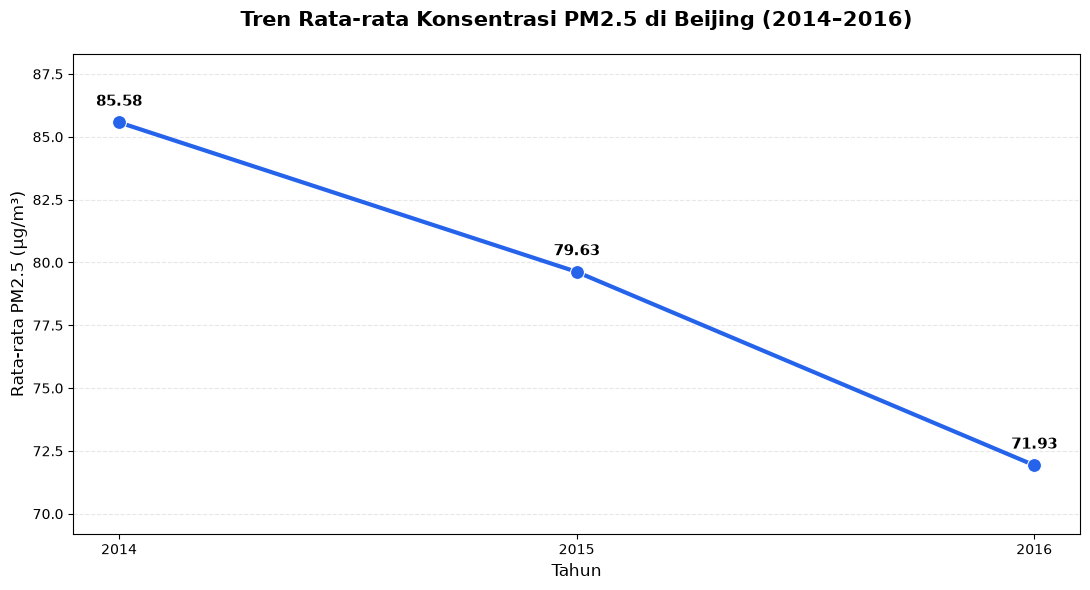

In [36]:
# Menyiapkan data visualisasi
annual_plot = annual_complete.copy()

# Membuat figure
plt.figure(figsize=(11, 6))

# Membuat line chart
sns.lineplot(
    data=annual_plot,
    x="year",
    y="mean_pm25",
    marker="o",
    markersize=10,
    linewidth=3,
    color="#2563EB"
)

# Menambahkan label nilai pada setiap titik
for _, row in annual_plot.iterrows():
    plt.annotate(
        f"{row['mean_pm25']:.2f}",
        xy=(row["year"], row["mean_pm25"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Judul dan label
plt.title(
    "Tren Rata-rata Konsentrasi PM2.5 di Beijing (2014–2016)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Tahun", fontsize=12)
plt.ylabel("Rata-rata PM2.5 (µg/m³)", fontsize=12)

# Mengatur tahun pada sumbu X
plt.xticks([2014, 2015, 2016])

# Menampilkan grid horizontal
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Memberikan ruang pada label
plt.margins(y=0.2)

# Merapikan layout
plt.tight_layout()

plt.show()

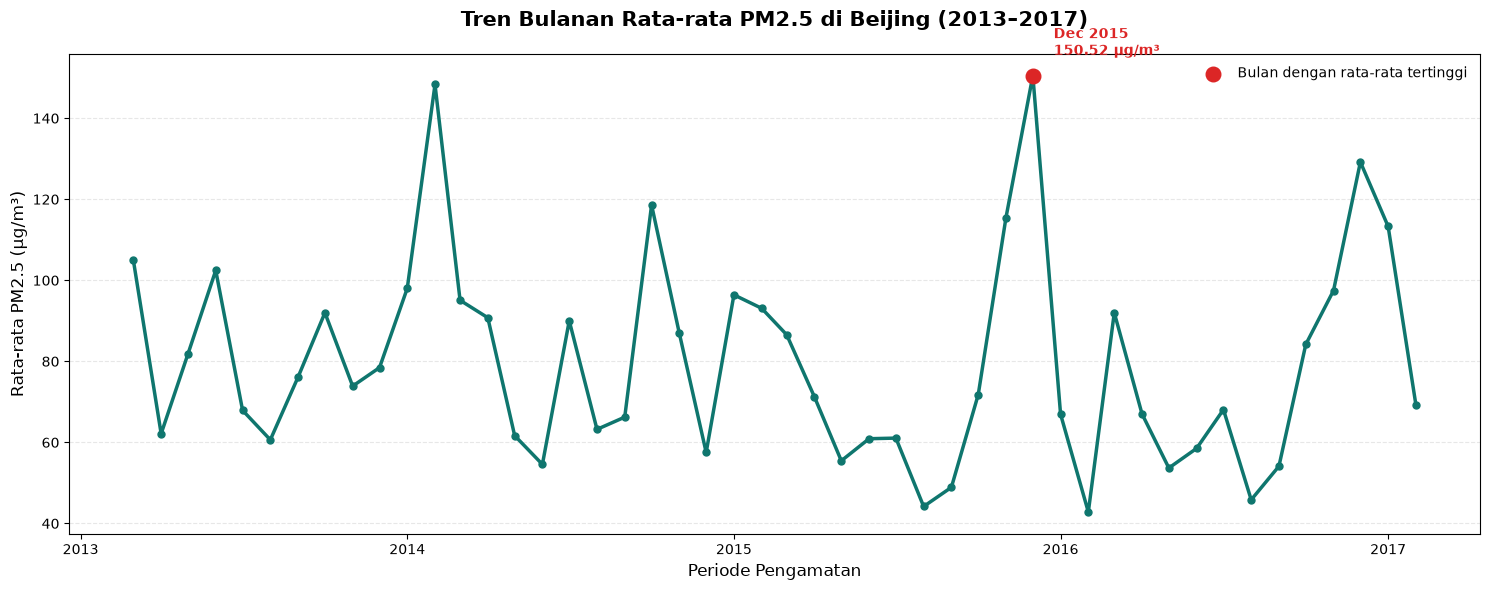

In [37]:
import matplotlib.dates as mdates

# Menyiapkan data bulanan
monthly_plot = monthly_pm25.copy()

# Membuat figure
plt.figure(figsize=(15, 6))

# Membuat line chart
sns.lineplot(
    data=monthly_plot,
    x="period",
    y="mean_pm25",
    color="#0F766E",
    linewidth=2.5
)

# Menambahkan marker pada setiap bulan
plt.scatter(
    monthly_plot["period"],
    monthly_plot["mean_pm25"],
    color="#0F766E",
    s=25,
    zorder=3
)

# Menandai bulan dengan rata-rata tertinggi
highest_month_plot = monthly_plot.loc[
    monthly_plot["mean_pm25"].idxmax()
]

plt.scatter(
    highest_month_plot["period"],
    highest_month_plot["mean_pm25"],
    color="#DC2626",
    s=110,
    zorder=5,
    label="Bulan dengan rata-rata tertinggi"
)

plt.annotate(
    (
        f"{highest_month_plot['period']:%b %Y}\n"
        f"{highest_month_plot['mean_pm25']:.2f} µg/m³"
    ),
    xy=(
        highest_month_plot["period"],
        highest_month_plot["mean_pm25"]
    ),
    xytext=(15, 15),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    color="#DC2626"
)

# Judul dan label
plt.title(
    "Tren Bulanan Rata-rata PM2.5 di Beijing (2013–2017)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Periode Pengamatan", fontsize=12)
plt.ylabel("Rata-rata PM2.5 (µg/m³)", fontsize=12)

# Mengatur format sumbu waktu
ax = plt.gca()

ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# Menambahkan grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.legend(frameon=False)

plt.tight_layout()
plt.show()

### Pertanyaan 2:
Stasiun pemantauan manakah yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, serta berapa besar selisih konsentrasi antara kedua stasiun tersebut?

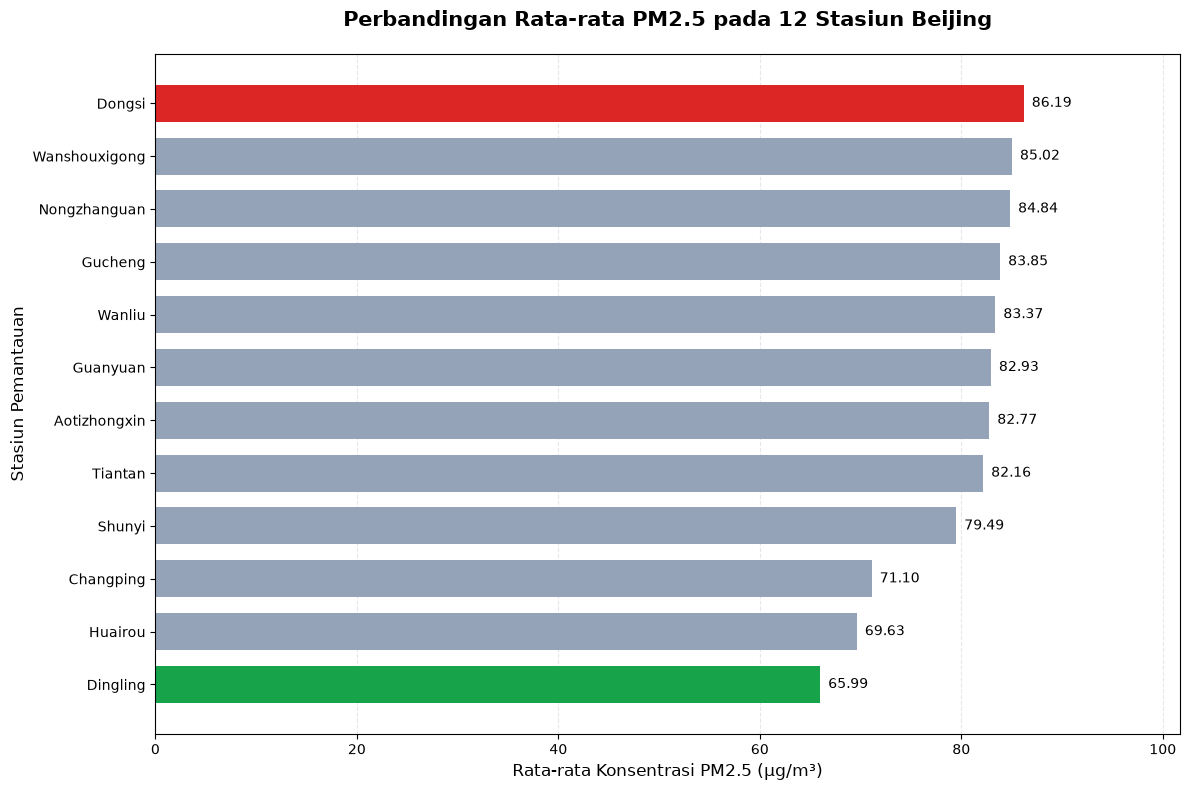

In [38]:
# Menyiapkan data
station_plot = station_pm25.copy()

# Mengurutkan dari tertinggi ke terendah
station_plot = station_plot.sort_values(
    by="mean_pm25",
    ascending=False
)

# Menentukan warna berdasarkan kategori
colors = []

for station in station_plot["station"]:

    if station == highest_station["station"]:
        colors.append("#DC2626")  # Merah: tertinggi

    elif station == lowest_station["station"]:
        colors.append("#16A34A")  # Hijau: terendah

    else:
        colors.append("#94A3B8")  # Abu-abu: lainnya

# Membuat figure
plt.figure(figsize=(12, 8))

# Membuat horizontal bar chart
bars = plt.barh(
    station_plot["station"],
    station_plot["mean_pm25"],
    color=colors,
    height=0.7
)

# Menambahkan label nilai
for bar in bars:

    width = bar.get_width()

    plt.text(
        width + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        fontsize=10
    )

# Menempatkan nilai tertinggi di atas
plt.gca().invert_yaxis()

# Judul dan label
plt.title(
    "Perbandingan Rata-rata PM2.5 pada 12 Stasiun Beijing",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Rata-rata Konsentrasi PM2.5 (µg/m³)",
    fontsize=12
)

plt.ylabel("Stasiun Pemantauan", fontsize=12)

# Menambahkan ruang untuk label
plt.xlim(
    0,
    station_plot["mean_pm25"].max() * 1.18
)

# Grid horizontal terhadap nilai X
plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

In [39]:
print("=== RINGKASAN ANALISIS ANTARSTASIUN ===")

print(
    f"Stasiun tertinggi: "
    f"{highest_station['station']}"
)

print(
    f"Rata-rata PM2.5 tertinggi: "
    f"{highest_station['mean_pm25']:.2f} µg/m³"
)

print(
    f"\nStasiun terendah: "
    f"{lowest_station['station']}"
)

print(
    f"Rata-rata PM2.5 terendah: "
    f"{lowest_station['mean_pm25']:.2f} µg/m³"
)

print(
    f"\nSelisih konsentrasi: "
    f"{pm25_difference:.2f} µg/m³"
)

print(
    f"Perbedaan relatif: "
    f"{percentage_difference:.2f}%"
)

=== RINGKASAN ANALISIS ANTARSTASIUN ===
Stasiun tertinggi: Dongsi
Rata-rata PM2.5 tertinggi: 86.19 µg/m³

Stasiun terendah: Dingling
Rata-rata PM2.5 terendah: 65.99 µg/m³

Selisih konsentrasi: 20.20 µg/m³
Perbedaan relatif: 30.62%


#### 1. Insight Visualisasi Tren Tahunan

Berdasarkan visualisasi rata-rata konsentrasi PM2.5 selama tahun kalender lengkap 2014–2016, diperoleh informasi bahwa:

1. Tahun dengan rata-rata konsentrasi PM2.5 tertinggi adalah **[TAHUN TERTINGGI]**, dengan nilai sebesar **[NILAI] µg/m³**.
2. Tahun dengan rata-rata konsentrasi PM2.5 terendah adalah **[TAHUN TERENDAH]**, dengan nilai sebesar **[NILAI] µg/m³**.
3. Perubahan rata-rata konsentrasi PM2.5 dari tahun 2014 ke 2015 adalah **[PERSENTASE]%**, sedangkan perubahan dari tahun 2015 ke 2016 adalah **[PERSENTASE]%**.

Hasil ini menunjukkan bahwa konsentrasi PM2.5 mengalami **[POLA PERUBAHAN BERDASARKAN GRAFIK]** selama periode perbandingan.

Temuan tersebut dapat digunakan sebagai dasar untuk mengevaluasi perubahan kualitas udara dan menentukan periode yang memerlukan perhatian lebih lanjut.


#### 2. Insight Visualisasi Tren Bulanan

Berdasarkan visualisasi rata-rata konsentrasi PM2.5 bulanan selama periode Maret 2013 hingga Februari 2017, diperoleh beberapa temuan:

1. Konsentrasi PM2.5 menunjukkan fluktuasi dari bulan ke bulan selama periode pengamatan.
2. Bulan dengan rata-rata konsentrasi PM2.5 tertinggi adalah **[BULAN DAN TAHUN]**, dengan nilai sebesar **[NILAI] µg/m³**.
3. Fluktuasi bulanan memberikan informasi tambahan yang tidak sepenuhnya terlihat melalui rata-rata tahunan.

Temuan ini menunjukkan pentingnya pemantauan kualitas udara secara berkala karena rata-rata tahunan dapat menyembunyikan variasi konsentrasi yang terjadi pada periode tertentu.

Hasil analisis bulanan dapat digunakan untuk membantu mengidentifikasi periode yang memerlukan pemantauan lebih intensif.


### Insight Visualization & Explanatory Analysis

Berdasarkan visualisasi yang telah dibuat, diperoleh beberapa informasi penting untuk menjawab pertanyaan bisnis.

**1. Perubahan Konsentrasi PM2.5 Berdasarkan Waktu**

Visualisasi tren tahunan memberikan gambaran mengenai perubahan rata-rata konsentrasi PM2.5 selama tahun kalender lengkap 2014–2016.

Sementara itu, visualisasi bulanan memperlihatkan fluktuasi konsentrasi PM2.5 dalam periode yang lebih pendek.

Kombinasi kedua visualisasi tersebut membantu memahami perubahan konsentrasi PM2.5 dari perspektif jangka panjang dan jangka pendek.

**2. Perbedaan Konsentrasi PM2.5 Antarstasiun**

Visualisasi horizontal bar chart menunjukkan perbandingan rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan.

Melalui visualisasi tersebut, stasiun dengan rata-rata konsentrasi tertinggi dan terendah dapat diidentifikasi secara langsung.

Perbandingan ini dapat digunakan sebagai dasar awal dalam menentukan lokasi prioritas pemantauan kualitas udara.

**3. Implikasi Hasil Analisis**

Hasil visualisasi dapat mendukung pengambilan keputusan terkait evaluasi kualitas udara berdasarkan periode waktu dan lokasi pemantauan.

Periode dengan konsentrasi relatif tinggi dan stasiun dengan rata-rata PM2.5 lebih tinggi dapat menjadi fokus pemantauan lebih lanjut.

Namun, rekomendasi perlu mempertimbangkan kelengkapan data serta keterbatasan analisis yang belum mengevaluasi hubungan sebab-akibat.

In [41]:
# Membuat salinan dataset analisis
advanced_df = pm25_df.copy()

# Menentukan batas kategori
bins = [0, 25, 50, 100, np.inf]

# Menentukan nama kategori
labels = [
    "Rendah",
    "Sedang",
    "Tinggi",
    "Sangat Tinggi"
]

# Mengelompokkan PM2.5 menggunakan pd.cut()
advanced_df["pm25_category"] = pd.cut(
    advanced_df["PM2.5"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

# Menampilkan hasil kategorisasi
advanced_df[
    ["station", "datetime", "PM2.5", "pm25_category"]
].head(10)

,station,datetime,PM2.5,pm25_category
0,Aotizhongxin,2013-03-01 00:00:00,4.0,Rendah
1,Aotizhongxin,2013-03-01 01:00:00,8.0,Rendah
2,Aotizhongxin,2013-03-01 02:00:00,7.0,Rendah
3,Aotizhongxin,2013-03-01 03:00:00,6.0,Rendah
4,Aotizhongxin,2013-03-01 04:00:00,3.0,Rendah
5,Aotizhongxin,2013-03-01 05:00:00,5.0,Rendah
6,Aotizhongxin,2013-03-01 06:00:00,3.0,Rendah
7,Aotizhongxin,2013-03-01 07:00:00,3.0,Rendah
8,Aotizhongxin,2013-03-01 08:00:00,3.0,Rendah
9,Aotizhongxin,2013-03-01 09:00:00,3.0,Rendah


In [42]:
# Memeriksa jumlah data setelah kategorisasi
print("Total pengamatan:", len(advanced_df))

print(
    "Jumlah kategori kosong:",
    advanced_df["pm25_category"].isna().sum()
)

print(
    "\nJumlah pengamatan per kategori:"
)

print(
    advanced_df["pm25_category"].value_counts(
        sort=False
    )
)

Total pengamatan: 412029
Jumlah kategori kosong: 0

Jumlah pengamatan per kategori:
pm25_category
Rendah           122272
Sedang            72609
Tinggi            99917
Sangat Tinggi    117231
Name: count, dtype: int64


In [43]:
# Menghitung jumlah pengamatan setiap kategori
category_distribution = (
    advanced_df["pm25_category"]
    .value_counts(sort=False)
    .reset_index()
)

# Mengubah nama kolom
category_distribution.columns = [
    "category",
    "count"
]

# Menghitung persentase
category_distribution["percentage"] = (
    category_distribution["count"]
    / len(advanced_df)
    * 100
)

# Menampilkan hasil
category_distribution.round(2)

,category,count,percentage
0,Rendah,122272,29.68
1,Sedang,72609,17.62
2,Tinggi,99917,24.25
3,Sangat Tinggi,117231,28.45


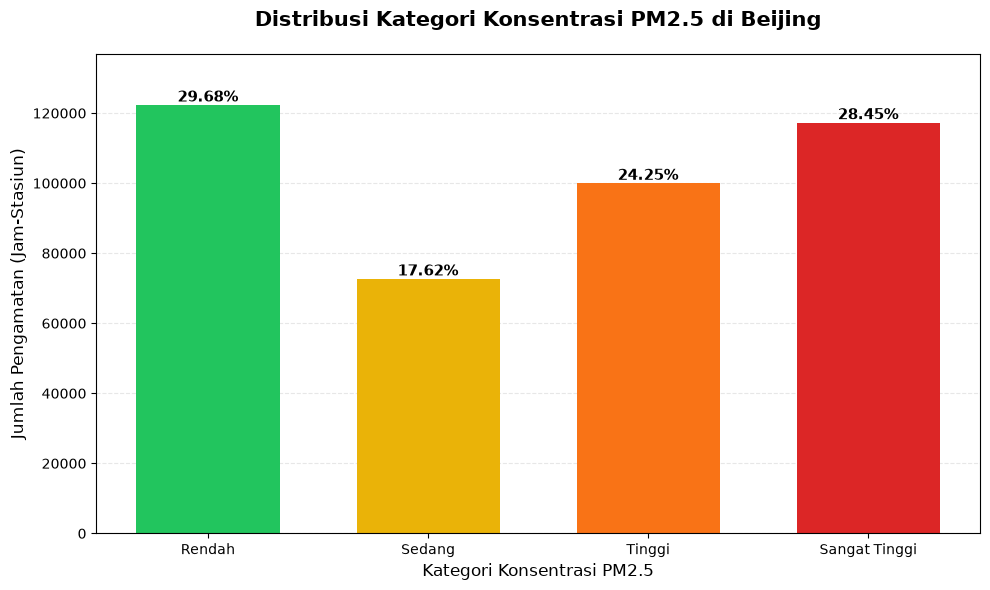

In [44]:
# Menentukan warna kategori
category_colors = [
    "#22C55E",
    "#EAB308",
    "#F97316",
    "#DC2626"
]

# Membuat figure
plt.figure(figsize=(10, 6))

# Membuat bar chart
bars = plt.bar(
    category_distribution["category"].astype(str),
    category_distribution["count"],
    color=category_colors,
    width=0.65
)

# Menambahkan label persentase
for bar, percentage in zip(
    bars,
    category_distribution["percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Judul dan label
plt.title(
    "Distribusi Kategori Konsentrasi PM2.5 di Beijing",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Kategori Konsentrasi PM2.5", fontsize=12)
plt.ylabel("Jumlah Pengamatan (Jam-Stasiun)", fontsize=12)

# Menambahkan grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.gca().set_axisbelow(True)

plt.margins(y=0.12)

plt.tight_layout()
plt.show()

In [45]:
# Menghitung jumlah pengamatan per kategori pada setiap stasiun
station_category_count = pd.crosstab(
    advanced_df["station"],
    advanced_df["pm25_category"]
)

# Menghitung persentase setiap kategori per stasiun
station_category_percentage = (
    station_category_count.div(
        station_category_count.sum(axis=1),
        axis=0
    ) * 100
)

# Memastikan urutan kategori konsisten
station_category_percentage = (
    station_category_percentage.reindex(
        columns=labels,
        fill_value=0
    )
)

# Menampilkan hasil
station_category_percentage.round(2)

pm25_category,Rendah,Sedang,Tinggi,Sangat Tinggi
station,,,,
Aotizhongxin,28.16,17.38,24.83,29.63
Changping,34.01,18.56,22.60,24.83
Dingling,38.77,17.60,20.99,22.63
Dongsi,27.48,16.58,24.77,31.17
Guanyuan,27.06,17.93,25.10,29.91
Gucheng,26.22,18.18,25.31,30.29
Huairou,34.17,18.46,23.19,24.17
Nongzhanguan,27.85,17.31,24.79,30.05
Shunyi,30.55,16.92,23.91,28.62


In [46]:
# Memastikan total persentase setiap stasiun = 100%
percentage_validation = (
    station_category_percentage.sum(axis=1)
)

print("Total persentase setiap stasiun:")
print(percentage_validation.round(2))

Total persentase setiap stasiun:
station
Aotizhongxin     100.0
Changping        100.0
Dingling         100.0
Dongsi           100.0
Guanyuan         100.0
Gucheng          100.0
Huairou          100.0
Nongzhanguan     100.0
Shunyi           100.0
Tiantan          100.0
Wanliu           100.0
Wanshouxigong    100.0
dtype: float64


In [47]:
# Membuat tabel khusus proporsi konsentrasi tinggi
high_pm25_station = station_category_percentage.copy()

# Menggabungkan kategori Tinggi dan Sangat Tinggi
high_pm25_station["high_pm25_percentage"] = (
    high_pm25_station["Tinggi"]
    + high_pm25_station["Sangat Tinggi"]
)

# Mengurutkan berdasarkan persentase tertinggi
high_pm25_station = (
    high_pm25_station[
        ["high_pm25_percentage"]
    ]
    .sort_values(
        by="high_pm25_percentage",
        ascending=False
    )
    .reset_index()
)

high_pm25_station.round(2)

pm25_category,station,high_pm25_percentage
0,Dongsi,55.94
1,Gucheng,55.60
2,Wanshouxigong,55.58
3,Guanyuan,55.02
4,Wanliu,55.01
5,Tiantan,54.92
6,Nongzhanguan,54.85
7,Aotizhongxin,54.46
8,Shunyi,52.53
9,Changping,47.43


In [48]:
# Mengambil stasiun dengan proporsi tertinggi
highest_high_pm25_station = high_pm25_station.iloc[0]

# Mengambil stasiun dengan proporsi terendah
lowest_high_pm25_station = high_pm25_station.iloc[-1]

print("=== HASIL ANALISIS LANJUTAN ===")

print("\nStasiun dengan proporsi PM2.5 > 50 tertinggi:")
print(highest_high_pm25_station["station"])

print(
    f"Persentase: "
    f"{highest_high_pm25_station['high_pm25_percentage']:.2f}%"
)

print("\nStasiun dengan proporsi PM2.5 > 50 terendah:")
print(lowest_high_pm25_station["station"])

print(
    f"Persentase: "
    f"{lowest_high_pm25_station['high_pm25_percentage']:.2f}%"
)

=== HASIL ANALISIS LANJUTAN ===

Stasiun dengan proporsi PM2.5 > 50 tertinggi:
Dongsi
Persentase: 55.94%

Stasiun dengan proporsi PM2.5 > 50 terendah:
Dingling
Persentase: 43.62%


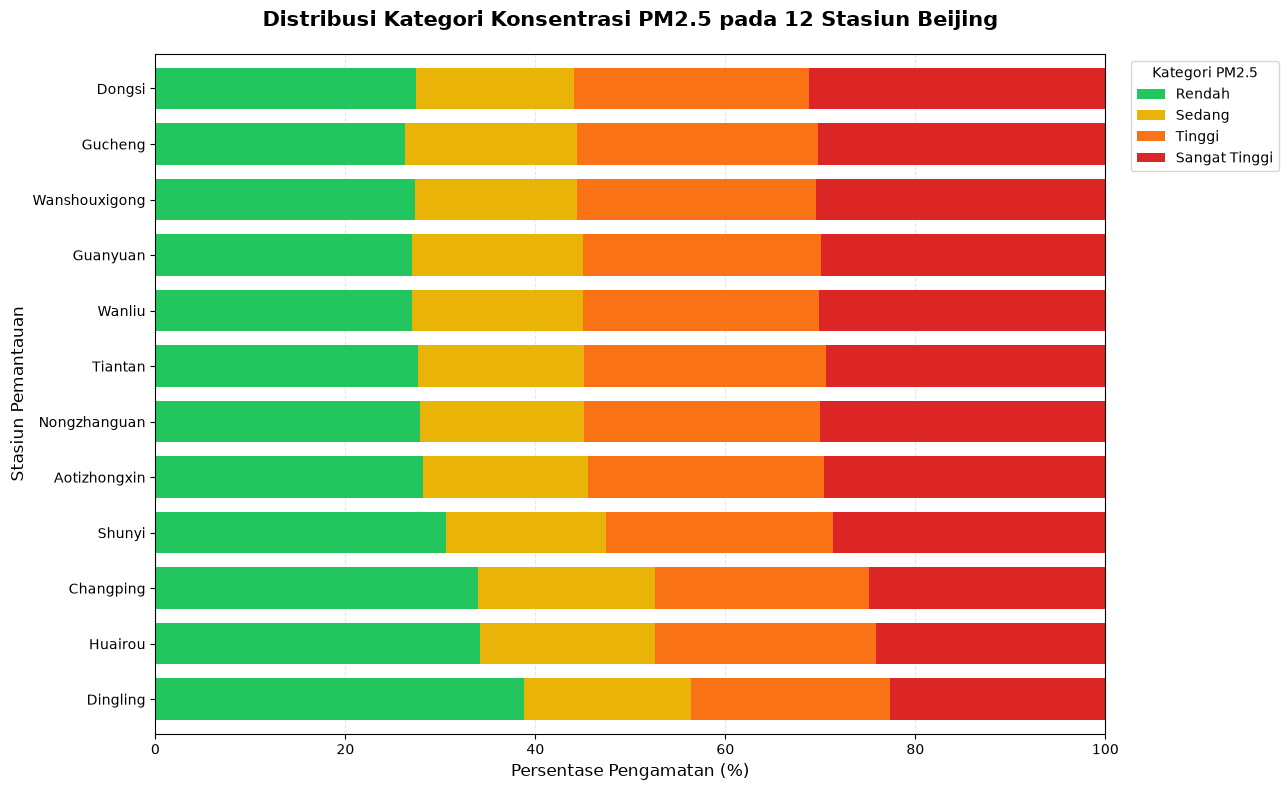

In [49]:
# Menyiapkan data visualisasi
station_category_plot = (
    station_category_percentage.copy()
)

# Menghitung persentase kategori tinggi
station_category_plot["high_total"] = (
    station_category_plot["Tinggi"]
    + station_category_plot["Sangat Tinggi"]
)

# Mengurutkan berdasarkan kategori tinggi
station_category_plot = (
    station_category_plot.sort_values(
        by="high_total",
        ascending=False
    )
)

# Mengambil hanya empat kategori
station_category_plot = station_category_plot[labels]

# Membuat visualisasi
ax = station_category_plot.plot(
    kind="barh",
    stacked=True,
    figsize=(13, 8),
    color=[
        "#22C55E",
        "#EAB308",
        "#F97316",
        "#DC2626"
    ],
    width=0.75
)

# Menempatkan stasiun dengan proporsi tinggi terbesar di atas
ax.invert_yaxis()

# Judul dan label
plt.title(
    "Distribusi Kategori Konsentrasi PM2.5 pada 12 Stasiun Beijing",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Persentase Pengamatan (%)", fontsize=12)
plt.ylabel("Stasiun Pemantauan", fontsize=12)

# Mengatur sumbu X
plt.xlim(0, 100)

# Menambahkan grid
plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Menambahkan legenda
plt.legend(
    title="Kategori PM2.5",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [50]:
# Menyimpan dataset yang sudah dikategorikan
advanced_df.to_csv(
    "pm25_categorized.csv",
    index=False
)

# Menyimpan distribusi kategori keseluruhan
category_distribution.to_csv(
    "pm25_category_distribution.csv",
    index=False
)

# Menyimpan distribusi kategori per stasiun
station_category_percentage.to_csv(
    "pm25_station_category_percentage.csv"
)

# Menyimpan peringkat proporsi konsentrasi tinggi
high_pm25_station.to_csv(
    "pm25_high_concentration_stations.csv",
    index=False
)

print("Seluruh hasil analisis lanjutan berhasil disimpan!")

Seluruh hasil analisis lanjutan berhasil disimpan!


### Insight Analisis Lanjutan

Berdasarkan analisis lanjutan menggunakan teknik Manual Grouping & Binning, diperoleh beberapa temuan sebagai berikut.

**1. Distribusi Kategori Konsentrasi PM2.5**

Pengelompokan konsentrasi PM2.5 dilakukan menggunakan empat kategori eksploratif, yaitu Rendah, Sedang, Tinggi, dan Sangat Tinggi.

Berdasarkan hasil perhitungan, kategori dengan jumlah pengamatan terbanyak adalah **[KATEGORI DOMINAN]**, dengan persentase sebesar **[PERSENTASE]%** dari seluruh pengamatan PM2.5 valid.

Temuan ini menunjukkan bahwa sebagian besar pengamatan berada pada kelompok konsentrasi **[KATEGORI DOMINAN]** selama periode pengamatan.

**2. Perbedaan Distribusi Kategori Antarstasiun**

Hasil analisis menunjukkan adanya variasi distribusi kategori PM2.5 pada 12 stasiun pemantauan.

Perbedaan tersebut menunjukkan bahwa karakteristik konsentrasi PM2.5 pada setiap stasiun tidak sepenuhnya sama.

Analisis distribusi memberikan informasi tambahan yang tidak dapat diperoleh hanya melalui perbandingan nilai rata-rata.

**3. Stasiun dengan Proporsi Konsentrasi Tinggi Terbesar**

Stasiun dengan proporsi pengamatan PM2.5 di atas 50 µg/m³ terbesar adalah **[NAMA STASIUN]**, dengan persentase sebesar **[PERSENTASE]%**.

Sementara itu, stasiun dengan proporsi terendah adalah **[NAMA STASIUN]**, dengan persentase sebesar **[PERSENTASE]%**.

Hasil ini dapat digunakan sebagai informasi tambahan untuk mempertimbangkan prioritas pemantauan kualitas udara.

**4. Implikasi terhadap Analisis Sebelumnya**

Analisis lanjutan melengkapi hasil EDA dan visualisasi sebelumnya dengan menunjukkan distribusi konsentrasi PM2.5, bukan hanya nilai rata-ratanya.

Dengan demikian, evaluasi kualitas udara dapat mempertimbangkan dua indikator, yaitu rata-rata konsentrasi PM2.5 dan proporsi pengamatan dengan konsentrasi relatif tinggi.

### Kesimpulan Analisis Lanjutan

Teknik Manual Grouping & Binning berhasil digunakan untuk mengelompokkan konsentrasi PM2.5 ke dalam empat kategori eksploratif.

Hasil analisis memberikan gambaran tambahan mengenai distribusi konsentrasi PM2.5 dan perbedaannya antarstasiun.

Informasi ini dapat mendukung penyusunan rekomendasi pemantauan kualitas udara yang lebih terarah.

Namun, kategori yang digunakan tidak dimaksudkan sebagai klasifikasi kualitas udara resmi atau penilaian risiko kesehatan.

## Conclusion & Recommendation

### Kesimpulan dan Rekomendasi

Tahap Conclusion & Recommendation merupakan tahap akhir dari proses analisis data yang bertujuan untuk merangkum temuan utama serta memberikan rekomendasi berdasarkan hasil pengolahan dan eksplorasi data.

Analisis dilakukan menggunakan Beijing Multi-Site Air Quality Dataset yang mencakup 12 stasiun pemantauan selama periode 1 Maret 2013 hingga 28 Februari 2017.

Kesimpulan disusun berdasarkan dua pertanyaan bisnis utama:

1. Bagaimana perubahan rata-rata konsentrasi PM2.5 tahunan dan tahun manakah yang memiliki konsentrasi tertinggi selama tahun kalender lengkap 2014–2016?
2. Stasiun manakah yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah selama periode pengamatan, serta berapa selisih konsentrasi antara keduanya?

Selain itu, hasil analisis lanjutan menggunakan teknik Manual Grouping & Binning digunakan untuk memberikan informasi tambahan mengenai distribusi kategori konsentrasi PM2.5.

Rekomendasi disusun dengan mempertimbangkan hasil analisis temporal, perbandingan antarstasiun, dan proporsi pengamatan berkonsentrasi tinggi.


### Conclusion Pertanyaan Bisnis 1

**Bagaimana perubahan rata-rata konsentrasi PM2.5 tahunan di 12 stasiun pemantauan Beijing selama periode Maret 2013 hingga Februari 2017, dan pada tahun kalender lengkap 2014–2016 manakah konsentrasi rata-ratanya paling tinggi?**

Berdasarkan hasil analisis temporal, rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan di Beijing menunjukkan tren penurunan selama tahun kalender lengkap 2014–2016.

Pada tahun **2014**, rata-rata konsentrasi PM2.5 tercatat sebesar **85,58 µg/m³**, menjadikannya tahun dengan rata-rata konsentrasi tertinggi selama periode perbandingan.

Pada tahun **2015**, rata-rata konsentrasi PM2.5 menurun menjadi **79,63 µg/m³**, atau turun sekitar **6,95%** dibandingkan tahun sebelumnya.

Penurunan kembali terjadi pada tahun **2016**, ketika rata-rata konsentrasi PM2.5 mencapai **71,93 µg/m³**, atau turun sekitar **9,67%** dibandingkan tahun 2015.

Secara keseluruhan, rata-rata konsentrasi PM2.5 mengalami penurunan sekitar **15,95% dari tahun 2014 hingga 2016**.

Temuan ini menunjukkan adanya perbaikan pada indikator rata-rata konsentrasi PM2.5 yang tercatat selama tiga tahun kalender lengkap tersebut.

Namun, penurunan tersebut tidak secara langsung membuktikan adanya hubungan sebab-akibat dengan kebijakan lingkungan atau faktor tertentu karena penelitian ini bersifat deskriptif.

**Kesimpulan utama:** Tahun 2014 merupakan tahun dengan rata-rata konsentrasi PM2.5 tertinggi selama periode 2014–2016, dan rata-rata konsentrasi menunjukkan tren penurunan hingga tahun 2016.


### Conclusion Pertanyaan Bisnis 2

**Stasiun pemantauan manakah yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, serta berapa besar selisih konsentrasi antara kedua stasiun tersebut?**

Berdasarkan hasil analisis perbandingan terhadap 12 stasiun pemantauan kualitas udara di Beijing, ditemukan adanya perbedaan rata-rata konsentrasi PM2.5 antarstasiun selama periode pengamatan.

Stasiun **Dongsi** memiliki rata-rata konsentrasi PM2.5 tertinggi, yaitu sebesar **86,19 µg/m³**.

Sementara itu, stasiun **Dingling** memiliki rata-rata konsentrasi PM2.5 terendah, yaitu sebesar **65,99 µg/m³**.

Selisih rata-rata konsentrasi PM2.5 antara kedua stasiun tersebut mencapai **20,20 µg/m³**.

Jika dibandingkan secara relatif, rata-rata konsentrasi PM2.5 di Dongsi sekitar **30,62% lebih tinggi** dibandingkan Dingling.

Hasil ini menunjukkan adanya variasi konsentrasi PM2.5 antarstasiun pemantauan selama periode 2013–2017.

Berdasarkan analisis lanjutan menggunakan teknik Manual Grouping & Binning, Dongsi juga memiliki proporsi pengamatan dengan konsentrasi PM2.5 lebih dari 50 µg/m³ terbesar, yaitu sekitar **55,94%** dari seluruh pengamatan PM2.5 valid di stasiun tersebut.

Temuan ini memperkuat alasan untuk memprioritaskan Dongsi dalam evaluasi dan pemantauan kualitas udara lebih lanjut.

Namun, perbedaan konsentrasi antarstasiun belum dapat digunakan untuk menentukan penyebab polusi karena faktor sumber emisi, karakteristik wilayah, dan kondisi meteorologi belum dianalisis secara mendalam.

**Kesimpulan utama:** Dongsi merupakan stasiun dengan rata-rata konsentrasi PM2.5 tertinggi, sedangkan Dingling merupakan stasiun dengan rata-rata terendah. Selisih rata-rata keduanya mencapai 20,20 µg/m³ selama periode pengamatan.


### Kesimpulan Analisis Lanjutan

Analisis lanjutan menggunakan teknik Manual Grouping & Binning berhasil memberikan gambaran tambahan mengenai distribusi konsentrasi PM2.5 selama periode pengamatan.

Dari total **412.029 pengamatan PM2.5 valid**, diperoleh distribusi sebagai berikut:

1. Kategori Rendah (0–25 µg/m³): **29,68%**.
2. Kategori Sedang (>25–50 µg/m³): **17,62%**.
3. Kategori Tinggi (>50–100 µg/m³): **24,25%**.
4. Kategori Sangat Tinggi (>100 µg/m³): **28,45%**.

Hasil tersebut menunjukkan bahwa sekitar **52,70% pengamatan PM2.5 valid memiliki konsentrasi lebih dari 50 µg/m³**.

Analisis antarstasiun juga menunjukkan bahwa Dongsi memiliki proporsi pengamatan PM2.5 di atas 50 µg/m³ terbesar, yaitu sekitar **55,94%**.

Temuan ini menunjukkan bahwa Dongsi tidak hanya memiliki rata-rata konsentrasi PM2.5 tertinggi, tetapi juga memiliki proporsi pengamatan berkonsentrasi tinggi terbesar berdasarkan batas eksploratif yang digunakan.

Dengan demikian, teknik binning memberikan perspektif tambahan mengenai karakteristik distribusi konsentrasi PM2.5 yang tidak sepenuhnya terlihat melalui perhitungan rata-rata.

Kategori yang digunakan dalam analisis ini merupakan kategori eksploratif dan tidak dimaksudkan sebagai klasifikasi resmi kualitas udara atau penilaian risiko kesehatan.

### Rekomendasi Action Item

Berdasarkan hasil analisis temporal, perbandingan antarstasiun, dan kategorisasi konsentrasi PM2.5, terdapat beberapa rekomendasi yang dapat dipertimbangkan untuk mendukung pemantauan dan evaluasi kualitas udara.

#### 1. Memprioritaskan Evaluasi Kualitas Udara di Stasiun Dongsi

**Dasar Temuan:**

Stasiun Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi, yaitu 86,19 µg/m³, serta proporsi pengamatan PM2.5 di atas 50 µg/m³ terbesar, yaitu sekitar 55,94%.

**Rekomendasi Tindakan:**

Pengelola pemantauan kualitas udara dapat memprioritaskan Dongsi untuk evaluasi lebih lanjut melalui:

- Pemantauan berkala terhadap perubahan konsentrasi PM2.5.
- Identifikasi periode dengan konsentrasi PM2.5 relatif tinggi.
- Pemeriksaan faktor meteorologi dan potensi sumber emisi di sekitar lokasi pemantauan.
- Perbandingan hasil pemantauan Dongsi dengan stasiun lain secara berkala.

**Indikator Evaluasi:**

Perubahan rata-rata konsentrasi PM2.5 dan proporsi pengamatan di atas 50 µg/m³ pada periode pemantauan berikutnya.

#### 2. Melakukan Evaluasi Tren Konsentrasi PM2.5 Secara Berkala

**Dasar Temuan:**

Rata-rata konsentrasi PM2.5 mengalami penurunan sekitar 15,95% dari tahun 2014 hingga 2016.

**Rekomendasi Tindakan:**

Pengelola dapat melakukan evaluasi kualitas udara secara bulanan dan tahunan untuk memantau keberlanjutan perubahan konsentrasi PM2.5.

Evaluasi dapat dilakukan dengan:

- Membandingkan rata-rata PM2.5 pada periode yang setara.
- Mengidentifikasi bulan dengan konsentrasi relatif tinggi.
- Memantau perubahan konsentrasi pada setiap stasiun.
- Menyajikan hasil pemantauan melalui dashboard interaktif.

**Indikator Evaluasi:**

Rata-rata PM2.5 bulanan dan tahunan, persentase perubahan antarperiode, serta distribusi konsentrasi pada setiap stasiun.

#### 3. Meningkatkan Kelengkapan dan Kualitas Data Pemantauan

**Dasar Temuan:**

Dataset memiliki 8.739 missing values pada variabel PM2.5 atau sekitar 2,08% dari seluruh pengamatan.

**Rekomendasi Tindakan:**

Pengelola sistem pemantauan dapat melakukan evaluasi terhadap kelengkapan data melalui:

- Pemeriksaan berkala terhadap ketersediaan data sensor.
- Identifikasi waktu dan lokasi dengan missing values yang relatif tinggi.
- Pencatatan penyebab kegagalan pengukuran apabila informasi tersebut tersedia.
- Pemantauan persentase kelengkapan data pada setiap stasiun.

**Indikator Evaluasi:**

Persentase pengamatan PM2.5 valid pada setiap stasiun dan periode waktu.

### Prioritas Implementasi

Berdasarkan hasil analisis, tindakan yang dapat diprioritaskan adalah **evaluasi lebih lanjut terhadap kondisi PM2.5 di stasiun Dongsi**, karena stasiun tersebut memiliki rata-rata konsentrasi tertinggi dan proporsi pengamatan di atas 50 µg/m³ terbesar.

Evaluasi berkala dan peningkatan kelengkapan data juga diperlukan untuk mendukung pemantauan kualitas udara yang lebih konsisten.

Rekomendasi ini bersifat awal dan perlu dilengkapi dengan analisis faktor meteorologi, sumber emisi, serta data periode terbaru sebelum digunakan sebagai dasar keputusan kebijakan lingkungan.

**Visualisasi Pendukung**

In [51]:
print("=" * 55)
print("VALIDASI HASIL AKHIR ANALISIS PM2.5")
print("=" * 55)

# Pertanyaan bisnis 1
print("\nPERTANYAAN BISNIS 1: ANALISIS TEMPORAL")

for _, row in annual_complete.iterrows():
    print(
        f"Tahun {int(row['year'])}: "
        f"{row['mean_pm25']:.2f} µg/m³"
    )

print(
    f"\nTahun tertinggi: "
    f"{int(highest_year['year'])}"
)

print(
    f"Rata-rata tertinggi: "
    f"{highest_year['mean_pm25']:.2f} µg/m³"
)

# Pertanyaan bisnis 2
print("\nPERTANYAAN BISNIS 2: ANALISIS ANTARSTASIUN")

print(
    f"Stasiun tertinggi: "
    f"{highest_station['station']} "
    f"({highest_station['mean_pm25']:.2f} µg/m³)"
)

print(
    f"Stasiun terendah: "
    f"{lowest_station['station']} "
    f"({lowest_station['mean_pm25']:.2f} µg/m³)"
)

print(
    f"Selisih: {pm25_difference:.2f} µg/m³"
)

# Analisis lanjutan
print("\nANALISIS LANJUTAN")

print(
    f"Stasiun dengan proporsi PM2.5 > 50 tertinggi: "
    f"{highest_high_pm25_station['station']}"
)

print(
    f"Persentase: "
    f"{highest_high_pm25_station['high_pm25_percentage']:.2f}%"
)

print("\nValidasi selesai!")

VALIDASI HASIL AKHIR ANALISIS PM2.5

PERTANYAAN BISNIS 1: ANALISIS TEMPORAL
Tahun 2014: 85.58 µg/m³
Tahun 2015: 79.63 µg/m³
Tahun 2016: 71.93 µg/m³

Tahun tertinggi: 2014
Rata-rata tertinggi: 85.58 µg/m³

PERTANYAAN BISNIS 2: ANALISIS ANTARSTASIUN
Stasiun tertinggi: Dongsi (86.19 µg/m³)
Stasiun terendah: Dingling (65.99 µg/m³)
Selisih: 20.20 µg/m³

ANALISIS LANJUTAN
Stasiun dengan proporsi PM2.5 > 50 tertinggi: Dongsi
Persentase: 55.94%

Validasi selesai!
